In [ ]:
# If needed, uncomment and run:
# %pip install tensorflow scikit-learn pandas numpy matplotlib seaborn

import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score, roc_curve
)

warnings.filterwarnings("ignore")
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
sns.set_theme(style="whitegrid")

QUICK_RUN = True  # Change to False for the full 50/80-epoch experiments.
EPOCHS = 3 if QUICK_RUN else 50
BATCH_SIZE = 64


In [ ]:
df = pd.read_csv("adult.csv")
print("Original shape:", df.shape)
display(df.head())
display(df.dtypes)

Original shape: (48842, 15)


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


,0
age,int64
workclass,object
fnlwgt,int64
education,object
educational-num,int64
marital-status,object
occupation,object
relationship,object
race,object
gender,object


In [ ]:
# Standardize this CSV's column names to the names used in the project brief.
df.columns = (df.columns.str.strip().str.lower()
              .str.replace("-", ".", regex=False)
              .str.replace("_", ".", regex=False))
rename_map = {"educational.num": "education.num", "gender": "sex"}
df.rename(columns=rename_map, inplace=True)

# Strip leading/trailing whitespace from every text column.
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Replace raw missing-value markers with true missing values.
df.replace("?", np.nan, inplace=True)
print("Missing values before dropping:")
display(df.isnull().sum().sort_values(ascending=False))
print("Shape before dropna:", df.shape)

# As specified in the brief, remove rows with any missing values.
df.dropna(inplace=True)
print("Shape after dropna:", df.shape)

# Drop survey weight and duplicate text education field.
df.drop(columns=["fnlwgt", "education"], inplace=True)

# Normalize target labels, then encode <=50K as 0 and >50K as 1.
df["income"] = df["income"].str.replace(".", "", regex=False).str.strip()
df["income"] = (df["income"] == ">50K").astype(int)

print("Cleaned shape:", df.shape)
display(df.head())
display(df["income"].value_counts().rename(index={0:"<=50K (0)", 1:">50K (1)"}))

Missing values before dropping:


,0
occupation,2809
workclass,2799
native.country,857
fnlwgt,0
education,0
education.num,0
age,0
marital.status,0
relationship,0
sex,0


Shape before dropna: (48842, 15)
Shape after dropna: (45222, 15)
Cleaned shape: (45222, 13)


,age,workclass,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,25,Private,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,0
1,38,Private,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,0
2,28,Local-gov,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,1
3,44,Private,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,1
5,34,Private,6,Never-married,Other-service,Not-in-family,White,Male,0,0,30,United-States,0


,count
income,
<=50K (0),34014
>50K (1),11208


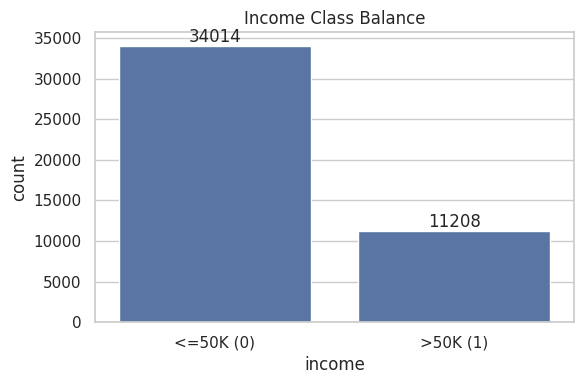

In [ ]:
plt.figure(figsize=(6,4))
ax = sns.countplot(data=df, x="income")
ax.set_xticklabels(["<=50K (0)", ">50K (1)"])
ax.set_title("Income Class Balance")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.show()

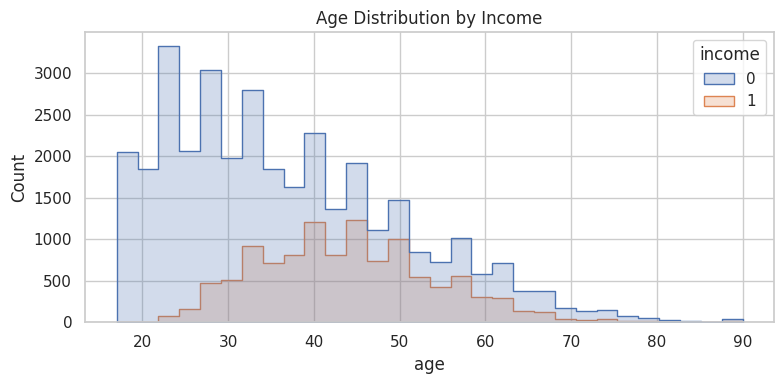

In [ ]:
plt.figure(figsize=(8,4))
sns.histplot(data=df, x="age", hue="income", bins=30, element="step", stat="count", common_norm=False)
plt.title("Age Distribution by Income")
plt.tight_layout()
plt.show()

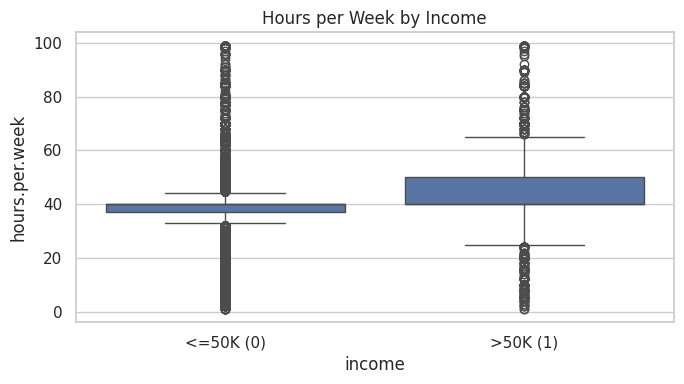

In [ ]:
plt.figure(figsize=(7,4))
sns.boxplot(data=df, x="income", y="hours.per.week")
plt.xticks([0,1], ["<=50K (0)", ">50K (1)"])
plt.title("Hours per Week by Income")
plt.tight_layout()
plt.show()

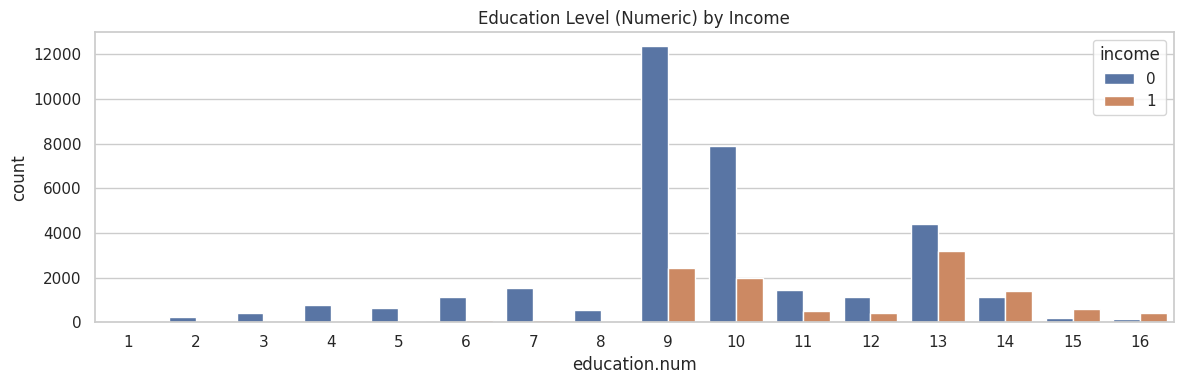

In [ ]:
plt.figure(figsize=(12,4))
sns.countplot(data=df, x="education.num", hue="income")
plt.title("Education Level (Numeric) by Income")
plt.tight_layout()
plt.show()

Encoded feature count: 80
X_train: (36177, 80) X_test: (9045, 80)
y_train: (36177,) y_test: (9045,)
Train class ratio:


,proportion
income,
0.0,0.752163
1.0,0.247837


Test class ratio:


,proportion
income,
0,0.752128
1,0.247872


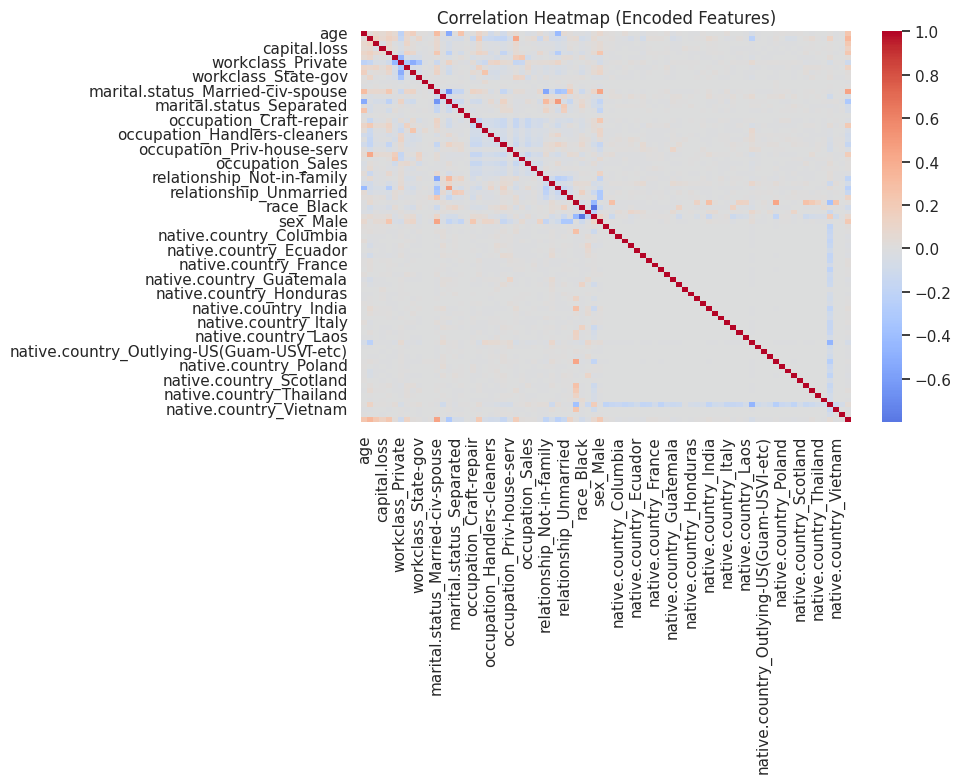

In [ ]:
X = df.drop(columns="income").copy()
y = df["income"].copy()

X = pd.get_dummies(X, drop_first=True, dtype=int)

numeric_cols = ["age", "education.num", "capital.gain", "capital.loss", "hours.per.week"]
# Split first, then fit the scaler ONLY on training data to prevent data leakage.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
scaler = StandardScaler()
X_train = X_train.copy()
X_test = X_test.copy()
X_train.loc[:, numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test.loc[:, numeric_cols] = scaler.transform(X_test[numeric_cols])

X_train = X_train.astype("float32")
X_test = X_test.astype("float32")
y_train = y_train.astype("float32")
y_test = y_test.astype("int32")

print("Encoded feature count:", X_train.shape[1])
print("X_train:", X_train.shape, "X_test:", X_test.shape)
print("y_train:", y_train.shape, "y_test:", y_test.shape)
print("Train class ratio:")
display(y_train.value_counts(normalize=True).sort_index())
print("Test class ratio:")
display(y_test.value_counts(normalize=True).sort_index())

plt.figure(figsize=(10,8))
corr_df = pd.concat([X_train.reset_index(drop=True), y_train.reset_index(drop=True).rename("income")], axis=1)
sns.heatmap(corr_df.corr(numeric_only=True), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap (Encoded Features)")
plt.tight_layout()
plt.show()

Task 2 — MLP Architecture: Baseline ANN

In [ ]:
def build_ann(input_dim, hidden_units=(128, 64), activation="relu",
              initializer="glorot_uniform", use_batch_norm=False,
              optimizer="adam", loss="binary_crossentropy"):
    layers = [keras.layers.Input(shape=(input_dim,))]
    for units in hidden_units:
        layers.append(keras.layers.Dense(units, kernel_initializer=initializer))
        if use_batch_norm:
            layers.append(keras.layers.BatchNormalization())
        layers.append(keras.layers.Activation(activation))
    layers.append(keras.layers.Dense(1, activation="sigmoid"))
    model = keras.Sequential(layers)
    model.compile(optimizer=optimizer, loss=loss, metrics=["accuracy"])
    return model

model_base = build_ann(input_dim=X_train.shape[1])
model_base.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        10,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,689 (73.00 KB)

 Trainable params: 18,689 (73.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/3
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8414 - loss: 0.3389 - val_accuracy: 0.8485 - val_loss: 0.3210
Epoch 2/3
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8533 - loss: 0.3148 - val_accuracy: 0.8477 - val_loss: 0.3205
Epoch 3/3
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8553 - loss: 0.3110 - val_accuracy: 0.8491 - val_loss: 0.3198


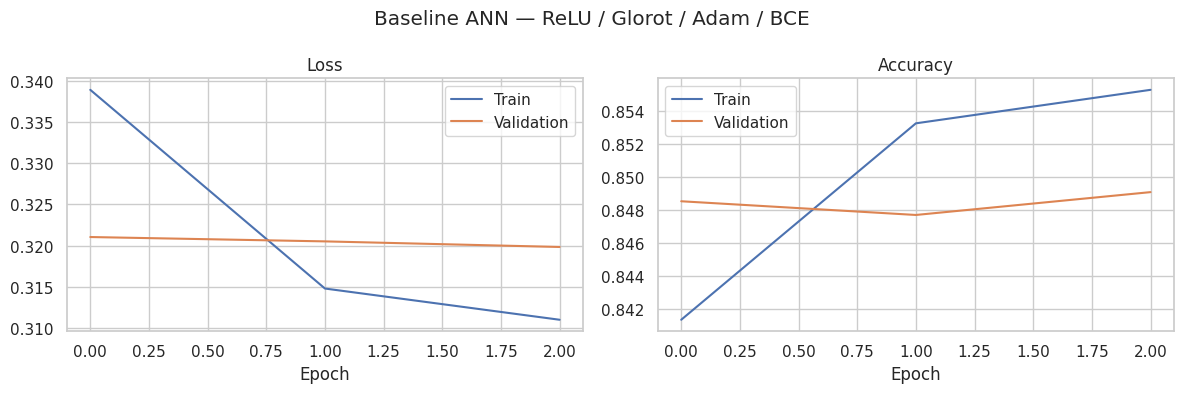

              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.90      6803
        >50K       0.74      0.61      0.67      2242

    accuracy                           0.85      9045
   macro avg       0.81      0.77      0.79      9045
weighted avg       0.84      0.85      0.85      9045



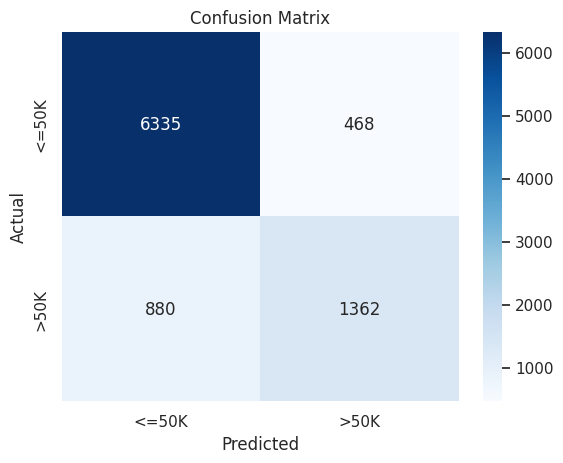

{'Test Acc': 0.8509673852957435, 'Prec(1)': 0.7442622950819672, 'Recall(1)': 0.6074933095450491, 'F1(1)': 0.668958742632613, 'ROC-AUC': np.float64(0.9088586226127084)}


In [ ]:
history_base = model_base.fit(
    X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
    validation_split=0.1, verbose=1
)

def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12,4))
    axes[0].plot(history.history["loss"], label="Train")
    axes[0].plot(history.history["val_loss"], label="Validation")
    axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
    axes[1].plot(history.history["accuracy"], label="Train")
    axes[1].plot(history.history["val_accuracy"], label="Validation")
    axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

def evaluate_model(model, X_eval=X_test, y_eval=y_test, threshold=0.5):
    prob = model.predict(X_eval, verbose=0).ravel()
    pred = (prob >= threshold).astype(int)
    metrics = {
        "Test Acc": accuracy_score(y_eval, pred),
        "Prec(1)": precision_score(y_eval, pred, zero_division=0),
        "Recall(1)": recall_score(y_eval, pred, zero_division=0),
        "F1(1)": f1_score(y_eval, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_eval, prob)
    }
    print(classification_report(y_eval, pred, target_names=["<=50K", ">50K"], zero_division=0))
    sns.heatmap(confusion_matrix(y_eval, pred), annot=True, fmt="d", cmap="Blues",
                xticklabels=["<=50K", ">50K"], yticklabels=["<=50K", ">50K"])
    plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix")
    plt.show()
    return metrics, prob, pred

plot_history(history_base, "Baseline ANN — ReLU / Glorot / Adam / BCE")
base_metrics, base_prob, base_pred = evaluate_model(model_base)
print(base_metrics)

Task 3 — Activation Functions

Training activation: relu
              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.90      6803
        >50K       0.74      0.61      0.67      2242

    accuracy                           0.85      9045
   macro avg       0.81      0.77      0.79      9045
weighted avg       0.84      0.85      0.85      9045



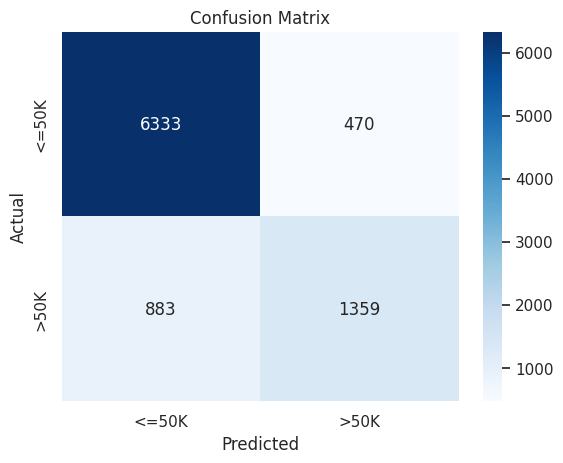

Training activation: tanh
              precision    recall  f1-score   support

       <=50K       0.88      0.92      0.90      6803
        >50K       0.72      0.63      0.67      2242

    accuracy                           0.85      9045
   macro avg       0.80      0.78      0.79      9045
weighted avg       0.84      0.85      0.85      9045



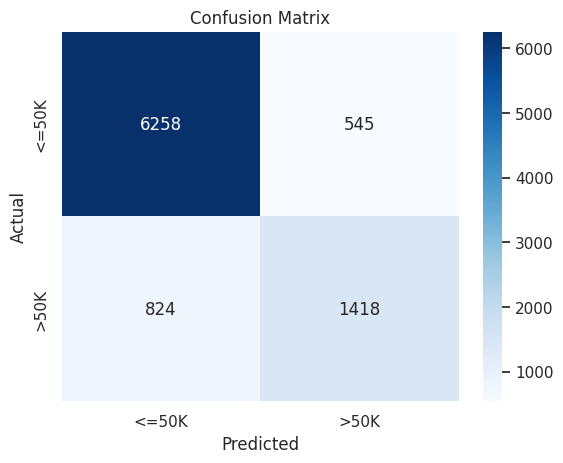

Training activation: sigmoid
              precision    recall  f1-score   support

       <=50K       0.88      0.91      0.90      6803
        >50K       0.70      0.64      0.67      2242

    accuracy                           0.84      9045
   macro avg       0.79      0.77      0.78      9045
weighted avg       0.84      0.84      0.84      9045



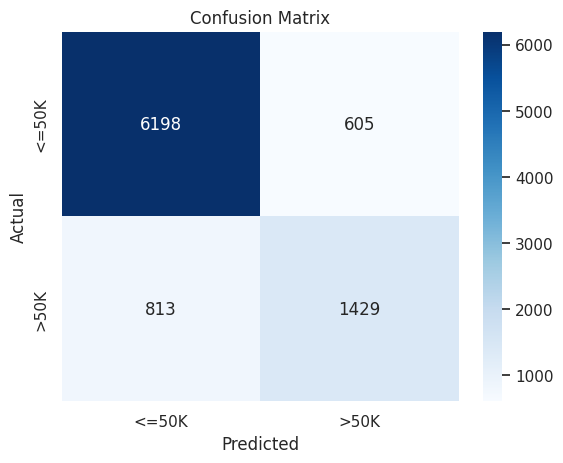

Training activation: elu
              precision    recall  f1-score   support

       <=50K       0.88      0.92      0.90      6803
        >50K       0.72      0.64      0.68      2242

    accuracy                           0.85      9045
   macro avg       0.80      0.78      0.79      9045
weighted avg       0.84      0.85      0.84      9045



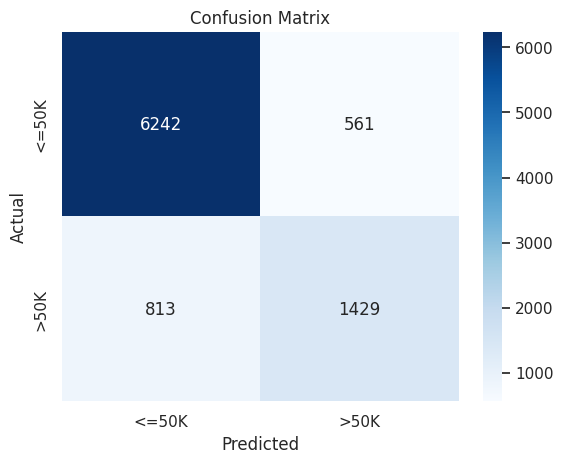

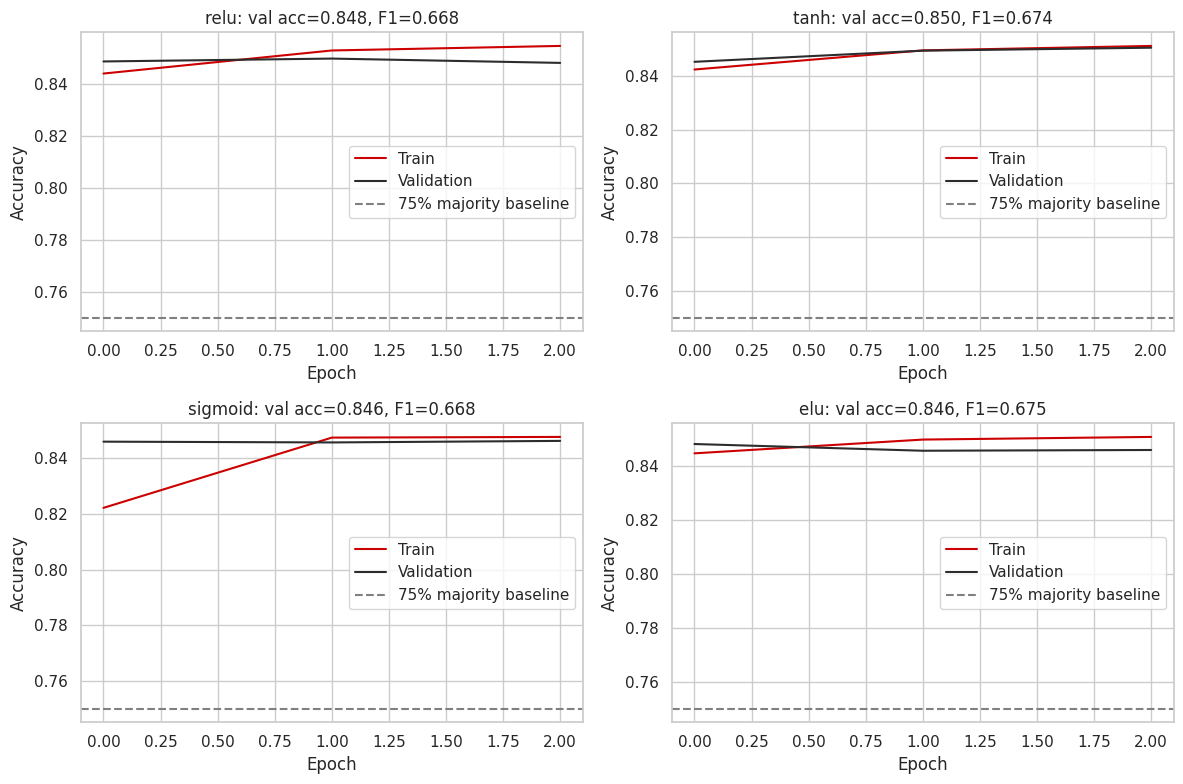

In [ ]:
results = []
activation_histories, activation_models, activation_metrics = {}, {}, {}
for act in ["relu", "tanh", "sigmoid", "elu"]:
    print("Training activation:", act)
    m = build_ann(X_train.shape[1], activation=act)
    h = m.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
              validation_split=0.1, verbose=0)
    activation_models[act], activation_histories[act] = m, h
    met, _, _ = evaluate_model(m)
    activation_metrics[act] = met
    if act != "relu":
        results.append({"Model":f"Activation - {act}", "Activation":act, "Init":"glorot_uniform",
                        "Loss":"binary_crossentropy", "BatchNorm":False, "Optimizer":"adam", **met})

fig, axes = plt.subplots(2,2,figsize=(12,8))
for ax, act in zip(axes.ravel(), ["relu","tanh","sigmoid","elu"]):
    h = activation_histories[act].history
    ax.plot(h["accuracy"], label="Train", color="#CC0000")
    ax.plot(h["val_accuracy"], label="Validation", color="#2C2C2C")
    ax.axhline(0.75, linestyle="--", color="gray", label="75% majority baseline")
    ax.set_title(f"{act}: val acc={h['val_accuracy'][-1]:.3f}, F1={activation_metrics[act]['F1(1)']:.3f}")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Accuracy"); ax.legend()
plt.tight_layout(); plt.show()

Fraction of zero-valued ReLU activations: 0.4675


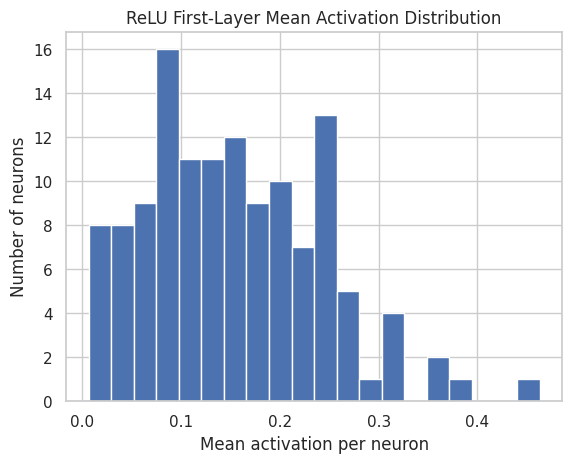

In [ ]:
# ReLU dead-neuron diagnostic on 500 test rows.
relu_model = activation_models["relu"]
hidden_model = keras.Model(inputs=relu_model.inputs, outputs=relu_model.layers[1].output)
hidden_activations = hidden_model.predict(X_test.iloc[:500], verbose=0)
dead_fraction = np.mean(hidden_activations == 0)
print("Fraction of zero-valued ReLU activations:", round(float(dead_fraction), 4))
plt.hist(hidden_activations.mean(axis=0), bins=20)
plt.title("ReLU First-Layer Mean Activation Distribution")
plt.xlabel("Mean activation per neuron"); plt.ylabel("Number of neurons")
plt.show()

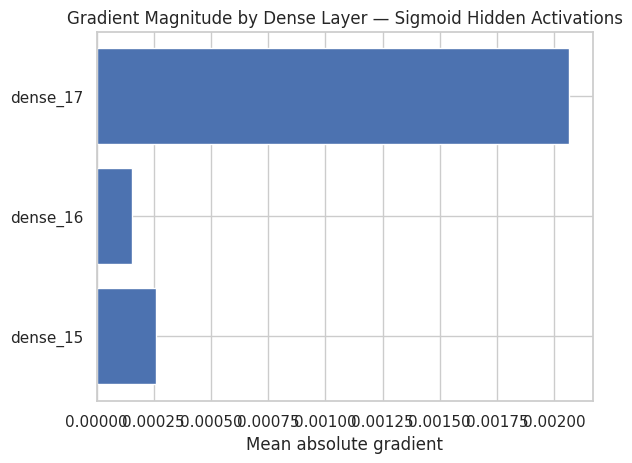

In [ ]:
# Gradient-flow check for sigmoid hidden activations.
sigmoid_model = activation_models["sigmoid"]
xb = tf.convert_to_tensor(X_train.iloc[:BATCH_SIZE].values, dtype=tf.float32)
yb = tf.convert_to_tensor(y_train.iloc[:BATCH_SIZE].values.reshape(-1,1), dtype=tf.float32)
with tf.GradientTape() as tape:
    pred = sigmoid_model(xb, training=True)
    loss_value = tf.reduce_mean(keras.losses.binary_crossentropy(yb, pred))
grads = tape.gradient(loss_value, sigmoid_model.trainable_variables)
grad_by_layer = {}
for layer, grad in zip([l for l in sigmoid_model.layers if isinstance(l, keras.layers.Dense)], grads[::2]):
    if grad is not None:
        grad_by_layer[layer.name] = float(tf.reduce_mean(tf.abs(grad)).numpy())
plt.barh(list(grad_by_layer.keys()), list(grad_by_layer.values()))
plt.title("Gradient Magnitude by Dense Layer — Sigmoid Hidden Activations")
plt.xlabel("Mean absolute gradient")
plt.show()

Task 4 — Weight Initialization

Training initializer: glorot_uniform
              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.90      6803
        >50K       0.74      0.61      0.67      2242

    accuracy                           0.85      9045
   macro avg       0.81      0.77      0.79      9045
weighted avg       0.85      0.85      0.85      9045



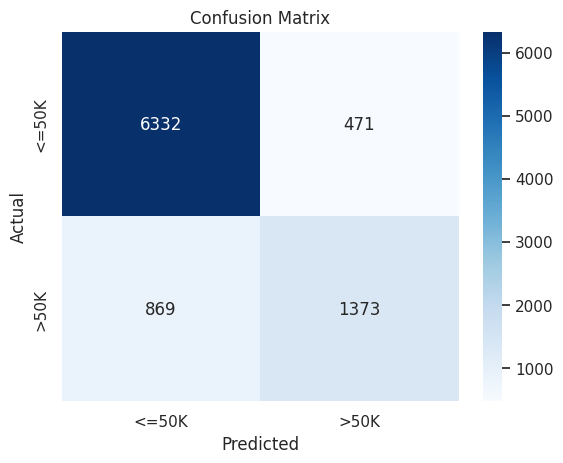

Training initializer: glorot_normal
              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.90      6803
        >50K       0.75      0.60      0.67      2242

    accuracy                           0.85      9045
   macro avg       0.81      0.77      0.79      9045
weighted avg       0.84      0.85      0.85      9045



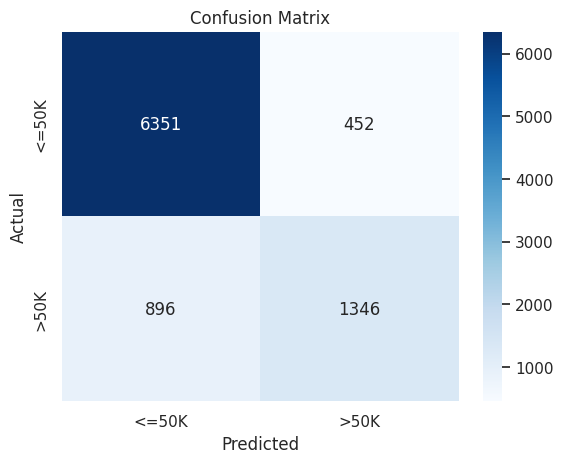

Training initializer: he_uniform
              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.90      6803
        >50K       0.75      0.60      0.66      2242

    accuracy                           0.85      9045
   macro avg       0.81      0.77      0.78      9045
weighted avg       0.84      0.85      0.84      9045



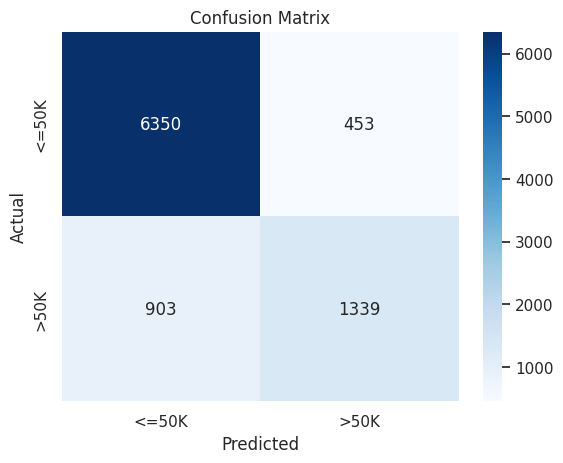

Training initializer: he_normal
              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.90      6803
        >50K       0.74      0.62      0.68      2242

    accuracy                           0.85      9045
   macro avg       0.81      0.78      0.79      9045
weighted avg       0.85      0.85      0.85      9045



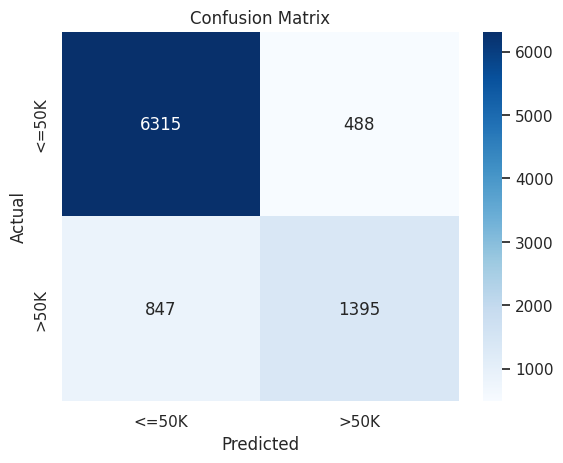

Training initializer: zeros
              precision    recall  f1-score   support

       <=50K       0.75      1.00      0.86      6803
        >50K       0.00      0.00      0.00      2242

    accuracy                           0.75      9045
   macro avg       0.38      0.50      0.43      9045
weighted avg       0.57      0.75      0.65      9045



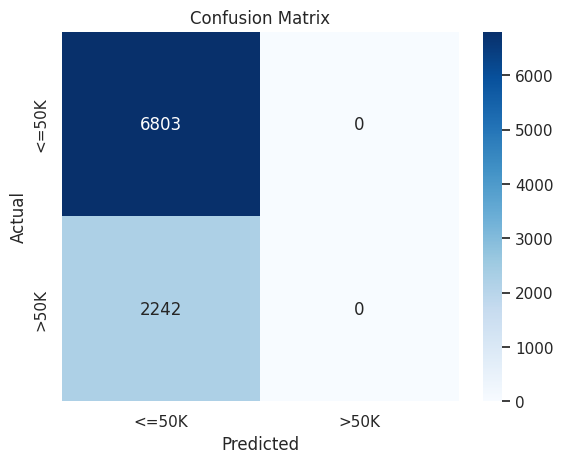

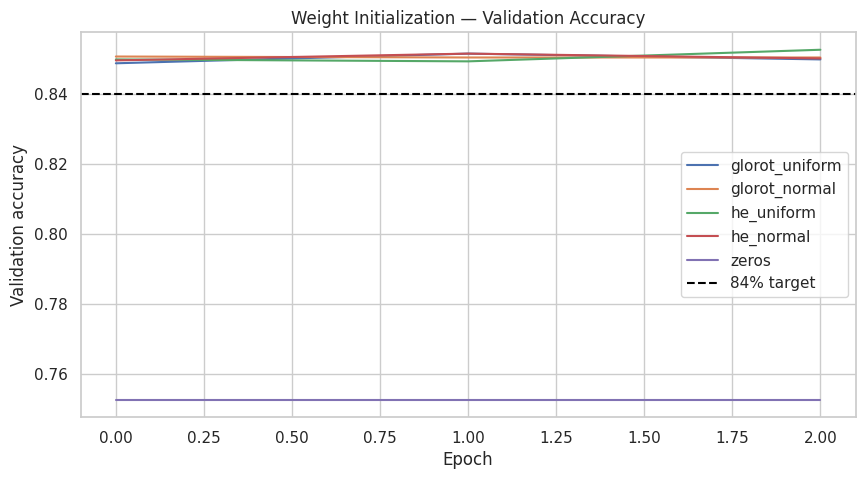

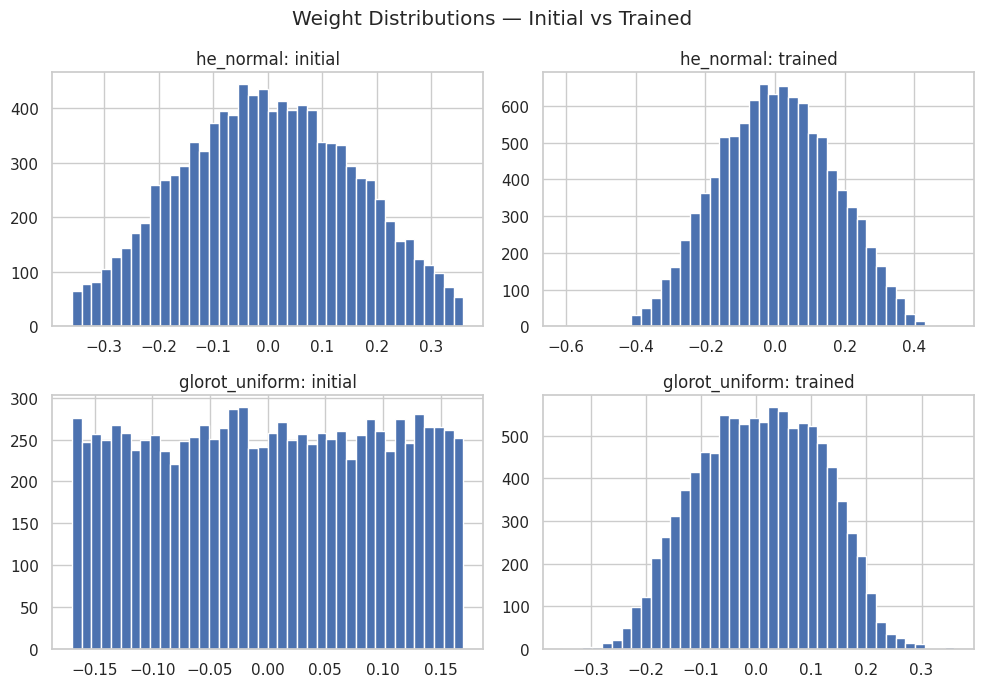

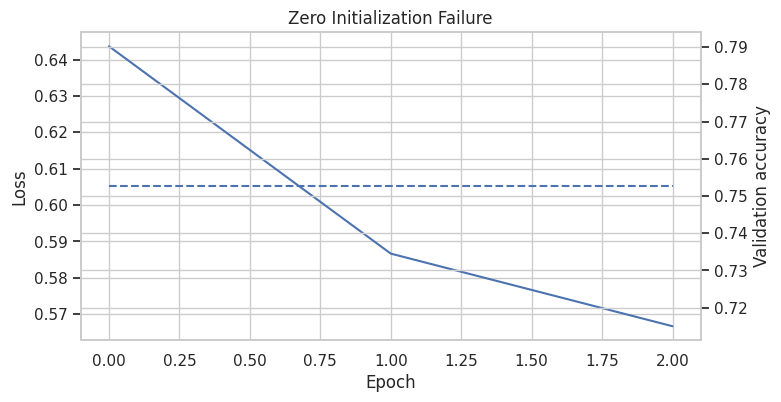

In [ ]:
init_names = ["glorot_uniform", "glorot_normal", "he_uniform", "he_normal", "zeros"]
init_models, init_histories, init_metrics = {}, {}, {}
init_before = {}
for init in init_names:
    print("Training initializer:", init)
    m = build_ann(X_train.shape[1], activation="relu", initializer=init)
    init_before[init] = m.layers[0].get_weights()[0].copy()
    h = m.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
              validation_split=0.1, verbose=0)
    init_models[init], init_histories[init] = m, h
    met, _, _ = evaluate_model(m)
    init_metrics[init] = met
    if init != "glorot_uniform":
        results.append({"Model":f"Initializer - {init}", "Activation":"relu", "Init":init,
                        "Loss":"binary_crossentropy", "BatchNorm":False, "Optimizer":"adam", **met})

plt.figure(figsize=(10,5))
for init, h in init_histories.items():
    plt.plot(h.history["val_accuracy"], label=init)
plt.axhline(0.84, linestyle="--", color="black", label="84% target")
plt.title("Weight Initialization — Validation Accuracy")
plt.xlabel("Epoch"); plt.ylabel("Validation accuracy"); plt.legend()
plt.show()

# Compare initial vs trained weight distributions for He Normal and Glorot Uniform.
fig, axes = plt.subplots(2,2,figsize=(10,7))
for row, init in enumerate(["he_normal", "glorot_uniform"]):
    axes[row,0].hist(init_before[init].ravel(), bins=40)
    axes[row,0].set_title(f"{init}: initial")
    axes[row,1].hist(init_models[init].layers[0].get_weights()[0].ravel(), bins=40)
    axes[row,1].set_title(f"{init}: trained")
plt.suptitle("Weight Distributions — Initial vs Trained")
plt.tight_layout(); plt.show()

zero_h = init_histories["zeros"].history
fig, ax1 = plt.subplots(figsize=(8,4))
ax1.plot(zero_h["loss"], label="Training loss")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss")
ax2 = ax1.twinx()
ax2.plot(zero_h["val_accuracy"], linestyle="--", label="Validation accuracy")
ax2.set_ylabel("Validation accuracy")
plt.title("Zero Initialization Failure")
plt.show()

Task 5 — Loss Functions

Class weights: {0: 0.6647495498144133, 1: 2.0174548293553425}
              precision    recall  f1-score   support

       <=50K       0.94      0.80      0.86      6803
        >50K       0.58      0.85      0.69      2242

    accuracy                           0.81      9045
   macro avg       0.76      0.82      0.78      9045
weighted avg       0.85      0.81      0.82      9045



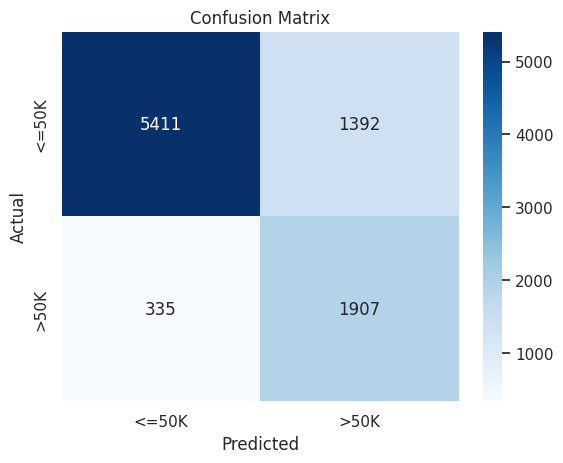

              precision    recall  f1-score   support

       <=50K       0.89      0.92      0.90      6803
        >50K       0.73      0.64      0.68      2242

    accuracy                           0.85      9045
   macro avg       0.81      0.78      0.79      9045
weighted avg       0.85      0.85      0.85      9045



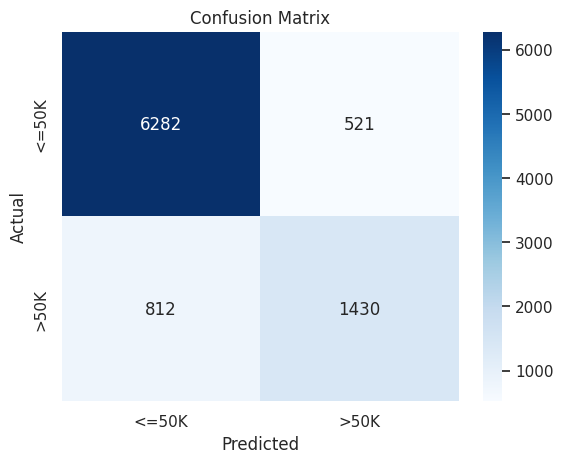

              precision    recall  f1-score   support

       <=50K       0.82      0.99      0.89      6803
        >50K       0.88      0.33      0.49      2242

    accuracy                           0.82      9045
   macro avg       0.85      0.66      0.69      9045
weighted avg       0.83      0.82      0.79      9045



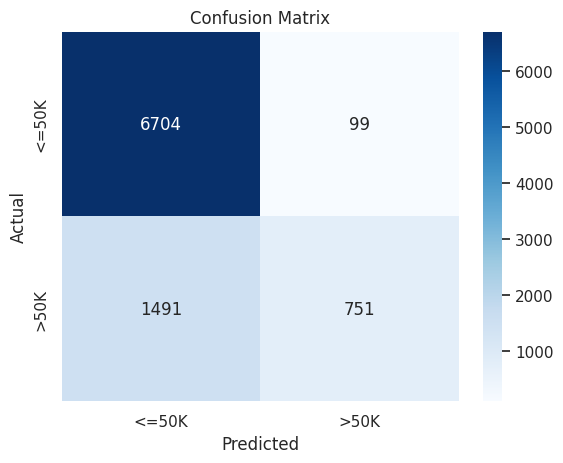

,Loss,Test Acc,Prec(1),Recall(1),F1(1),ROC-AUC
0,BCE baseline,0.850967,0.744262,0.607493,0.668959,0.908859
1,Weighted BCE,0.809066,0.578054,0.850580,0.688323,0.909508
2,MSE,0.852626,0.732957,0.637823,0.682089,0.909632
3,Focal Loss,0.824212,0.883529,0.334969,0.485770,0.908211


In [ ]:
# Weighted BCE using balanced class weights computed from training labels.
classes = np.array([0,1])
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train.astype(int))
class_weight_dict = {0: float(weights[0]), 1: float(weights[1])}
print("Class weights:", class_weight_dict)

model_wbce = build_ann(X_train.shape[1], activation="relu", initializer="he_normal")
hist_wbce = model_wbce.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
                            validation_split=0.1, class_weight=class_weight_dict, verbose=0)
met_wbce, prob_wbce, pred_wbce = evaluate_model(model_wbce)
results.append({"Model":"Weighted BCE", "Activation":"relu", "Init":"he_normal",
                "Loss":"binary_crossentropy + class_weight", "BatchNorm":False, "Optimizer":"adam", **met_wbce})

# MSE experiment
model_mse = build_ann(X_train.shape[1], activation="relu", initializer="he_normal",
                      loss="mean_squared_error")
hist_mse = model_mse.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
                          validation_split=0.1, verbose=0)
met_mse, prob_mse, pred_mse = evaluate_model(model_mse)
results.append({"Model":"MSE", "Activation":"relu", "Init":"he_normal",
                "Loss":"mean_squared_error", "BatchNorm":False, "Optimizer":"adam", **met_mse})

def focal_loss(gamma=2.0, alpha=0.25):
    def loss(y_true, y_pred):
        y_true = tf.cast(tf.reshape(y_true, (-1,1)), tf.float32)
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0-1e-7)
        bce = -(y_true * tf.math.log(y_pred) + (1-y_true) * tf.math.log(1-y_pred))
        weight = alpha*y_true*tf.pow(1-y_pred, gamma) + (1-alpha)*(1-y_true)*tf.pow(y_pred, gamma)
        return tf.reduce_mean(weight*bce)
    return loss

model_focal = build_ann(X_train.shape[1], activation="relu", initializer="he_normal",
                        loss=focal_loss(gamma=2.0, alpha=0.25))
hist_focal = model_focal.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
                             validation_split=0.1, verbose=0)
met_focal, prob_focal, pred_focal = evaluate_model(model_focal)
results.append({"Model":"Focal Loss", "Activation":"relu", "Init":"he_normal",
                "Loss":"focal_loss", "BatchNorm":False, "Optimizer":"adam", **met_focal})

# Compare class-1 F1 after training. (The brief asks for per-epoch F1 curves;
# these final metrics provide a clear first comparison without extra per-epoch prediction cost.)
compare_loss = pd.DataFrame([
    {"Loss":"BCE baseline", **base_metrics},
    {"Loss":"Weighted BCE", **met_wbce},
    {"Loss":"MSE", **met_mse},
    {"Loss":"Focal Loss", **met_focal},
])
display(compare_loss)

Task 6 — Batch Normalization

Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_45 (Dense)                │ (None, 128)            │        10,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_30 (Activation)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_31 (Activation)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_47 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,457 (76.00 KB)

 Trainable params: 19,073 (74.50 KB)

 Non-trainable params: 384 (1.50 KB)

              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.90      6803
        >50K       0.74      0.62      0.67      2242

    accuracy                           0.85      9045
   macro avg       0.81      0.77      0.79      9045
weighted avg       0.84      0.85      0.85      9045



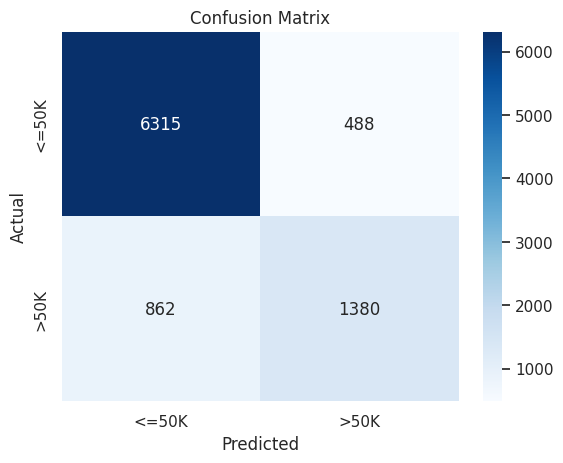

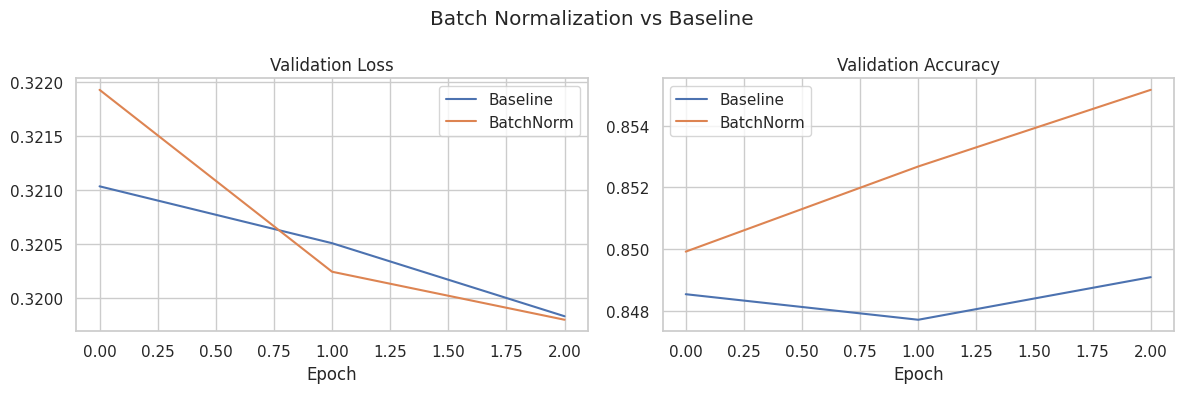

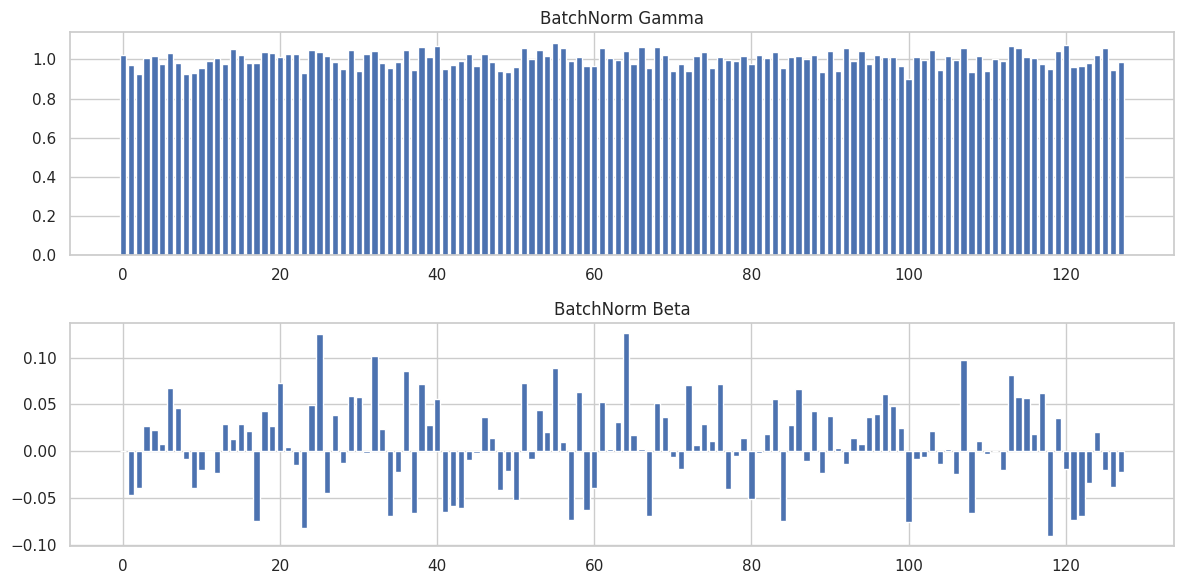

In [ ]:
model_bn = build_ann(X_train.shape[1], activation="relu", initializer="he_normal",
                     use_batch_norm=True, optimizer="adam", loss="binary_crossentropy")
model_bn.summary()
hist_bn = model_bn.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
                       validation_split=0.1, verbose=0)
met_bn, prob_bn, pred_bn = evaluate_model(model_bn)
results.append({"Model":"BatchNorm", "Activation":"relu", "Init":"he_normal",
                "Loss":"binary_crossentropy", "BatchNorm":True, "Optimizer":"adam", **met_bn})

fig, axes = plt.subplots(1,2,figsize=(12,4))
for h, label in [(history_base,"Baseline"),(hist_bn,"BatchNorm")]:
    axes[0].plot(h.history["val_loss"], label=label)
    axes[1].plot(h.history["val_accuracy"], label=label)
axes[0].set_title("Validation Loss"); axes[1].set_title("Validation Accuracy")
for ax in axes: ax.set_xlabel("Epoch"); ax.legend()
plt.suptitle("Batch Normalization vs Baseline")
plt.tight_layout(); plt.show()

# Inspect learned gamma and beta from the first BatchNormalization layer.
bn_layer = next(layer for layer in model_bn.layers if isinstance(layer, keras.layers.BatchNormalization))
gamma, beta, running_mean, running_var = bn_layer.get_weights()
fig, axes = plt.subplots(2,1,figsize=(12,6))
axes[0].bar(np.arange(len(gamma)), gamma); axes[0].set_title("BatchNorm Gamma")
axes[1].bar(np.arange(len(beta)), beta); axes[1].set_title("BatchNorm Beta")
plt.tight_layout(); plt.show()

Task 7 — Optimizers and Final Comparison

Training optimizer: SGD
              precision    recall  f1-score   support

       <=50K       0.87      0.93      0.90      6803
        >50K       0.74      0.56      0.64      2242

    accuracy                           0.84      9045
   macro avg       0.80      0.75      0.77      9045
weighted avg       0.83      0.84      0.83      9045



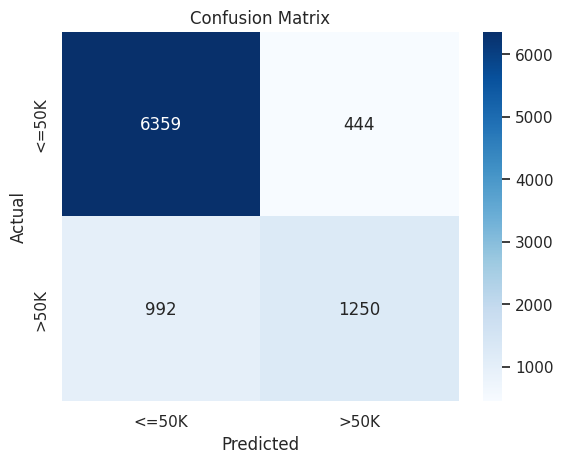

Training optimizer: SGD momentum
              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.90      6803
        >50K       0.74      0.60      0.66      2242

    accuracy                           0.85      9045
   macro avg       0.81      0.77      0.78      9045
weighted avg       0.84      0.85      0.84      9045



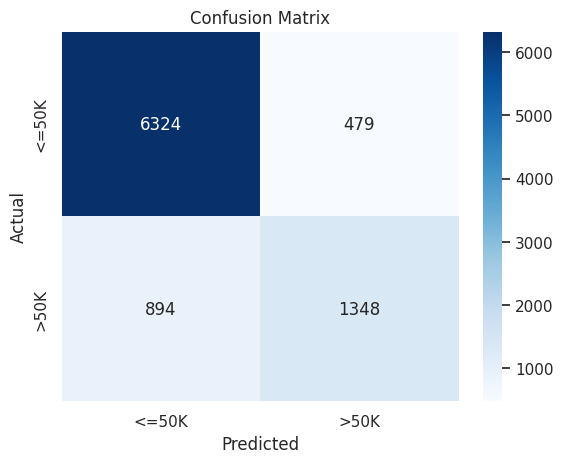

Training optimizer: RMSprop
              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.90      6803
        >50K       0.74      0.62      0.67      2242

    accuracy                           0.85      9045
   macro avg       0.81      0.77      0.79      9045
weighted avg       0.84      0.85      0.85      9045



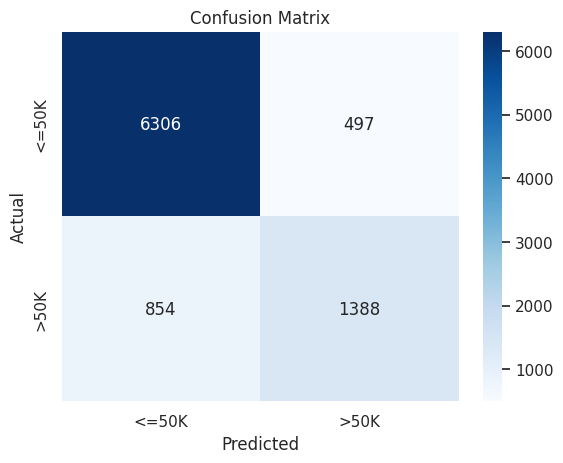

Training optimizer: Adam default
              precision    recall  f1-score   support

       <=50K       0.89      0.92      0.90      6803
        >50K       0.73      0.64      0.68      2242

    accuracy                           0.85      9045
   macro avg       0.81      0.78      0.79      9045
weighted avg       0.85      0.85      0.85      9045



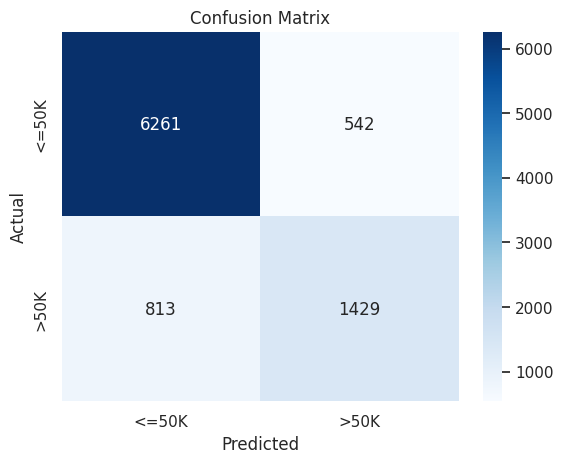

Training optimizer: Adam explicit
              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.90      6803
        >50K       0.73      0.62      0.67      2242

    accuracy                           0.85      9045
   macro avg       0.81      0.77      0.79      9045
weighted avg       0.84      0.85      0.85      9045



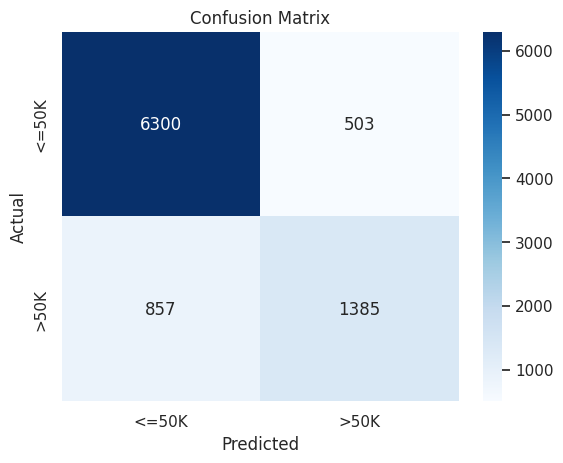

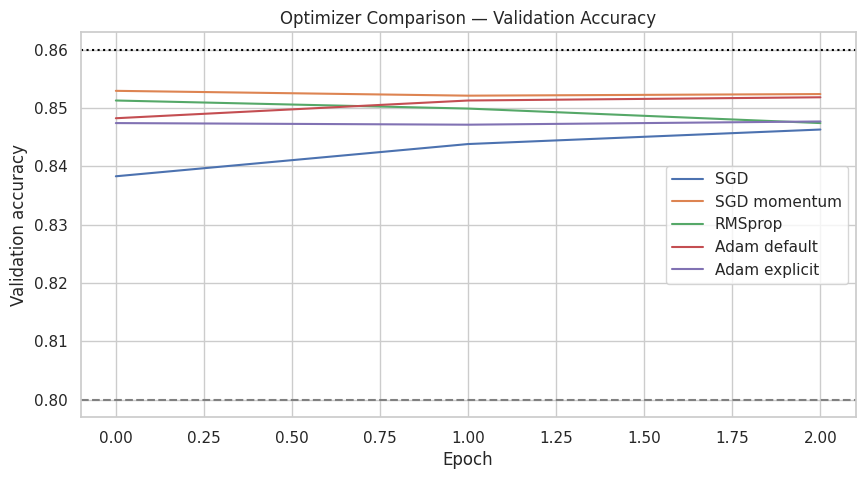

In [ ]:
# Compare five optimizer configurations.
optimizer_configs = {
    "SGD": "sgd",
    "SGD momentum": keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    "RMSprop": "rmsprop",
    "Adam default": "adam",
    "Adam explicit": keras.optimizers.Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.999)
}
opt_models, opt_histories, opt_metrics = {}, {}, {}
for name, opt in optimizer_configs.items():
    print("Training optimizer:", name)
    m = build_ann(X_train.shape[1], activation="relu", initializer="he_normal",
                  use_batch_norm=True, optimizer=opt)
    h = m.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
              validation_split=0.1, verbose=0)
    opt_models[name], opt_histories[name] = m, h
    met, _, _ = evaluate_model(m)
    opt_metrics[name] = met
    results.append({"Model":f"Optimizer - {name}", "Activation":"relu", "Init":"he_normal",
                    "Loss":"binary_crossentropy", "BatchNorm":True, "Optimizer":name, **met})

plt.figure(figsize=(10,5))
for name, h in opt_histories.items():
    plt.plot(h.history["val_accuracy"], label=name)
plt.axhline(0.80, linestyle="--", color="gray")
plt.axhline(0.86, linestyle=":", color="black")
plt.title("Optimizer Comparison — Validation Accuracy")
plt.xlabel("Epoch"); plt.ylabel("Validation accuracy"); plt.legend()
plt.show()

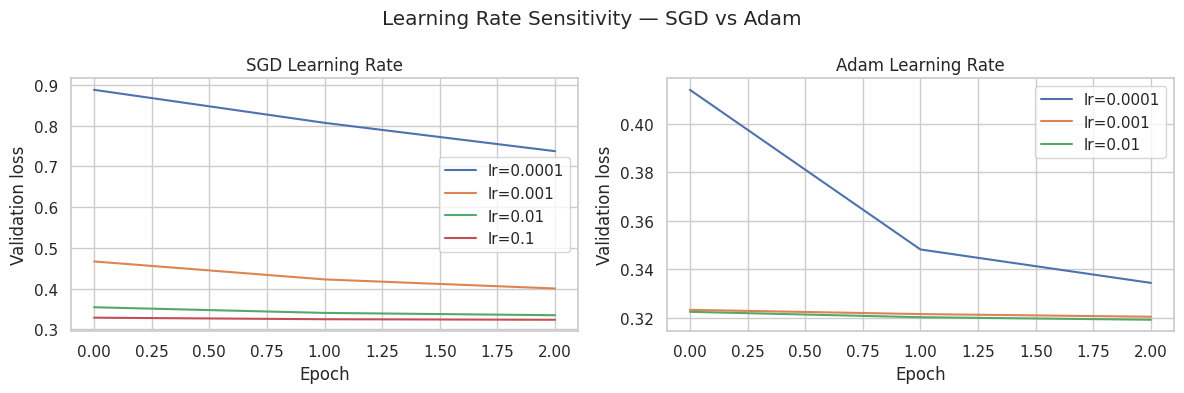

In [ ]:
# Learning-rate sensitivity: four SGD and three Adam settings.
lr_histories = {"SGD": {}, "Adam": {}}
for lr in [0.0001, 0.001, 0.01, 0.1]:
    m = build_ann(X_train.shape[1], activation="relu", initializer="he_normal",
                  use_batch_norm=True, optimizer=keras.optimizers.SGD(learning_rate=lr))
    h = m.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
              validation_split=0.1, verbose=0)
    lr_histories["SGD"][lr] = h

for lr in [0.0001, 0.001, 0.01]:
    m = build_ann(X_train.shape[1], activation="relu", initializer="he_normal",
                  use_batch_norm=True, optimizer=keras.optimizers.Adam(learning_rate=lr))
    h = m.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
              validation_split=0.1, verbose=0)
    lr_histories["Adam"][lr] = h

fig, axes = plt.subplots(1,2,figsize=(12,4))
for lr, h in lr_histories["SGD"].items():
    axes[0].plot(h.history["val_loss"], label=f"lr={lr}")
for lr, h in lr_histories["Adam"].items():
    axes[1].plot(h.history["val_loss"], label=f"lr={lr}")
axes[0].set_title("SGD Learning Rate"); axes[1].set_title("Adam Learning Rate")
for ax in axes: ax.set_xlabel("Epoch"); ax.set_ylabel("Validation loss"); ax.legend()
plt.suptitle("Learning Rate Sensitivity — SGD vs Adam")
plt.tight_layout(); plt.show()

Final combined model

Epoch 1/5
509/509 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.7952 - loss: 0.4037 - val_accuracy: 0.7946 - val_loss: 0.3953
Epoch 2/5
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8076 - loss: 0.3765 - val_accuracy: 0.7919 - val_loss: 0.3979
Epoch 3/5
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8116 - loss: 0.3680 - val_accuracy: 0.7955 - val_loss: 0.4000
Epoch 4/5
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8156 - loss: 0.3616 - val_accuracy: 0.7935 - val_loss: 0.4030
Epoch 5/5
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8188 - loss: 0.3560 - val_accuracy: 0.7933 - val_loss: 0.4055
              precision    recall  f1-score   support

       <=50K       0.95      0.76      0.85      6803
        >50K       0.55      0.88      0.68      2242

    accuracy                           0.79      9045
   macro avg       0.75      0.82      0.76      9045
weighted avg       0.85      0.79      0.80      9045



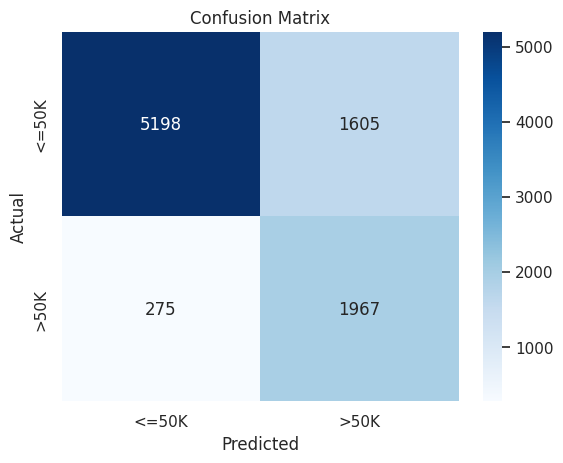

In [ ]:
model_final = build_ann(X_train.shape[1], hidden_units=(128,64), activation="relu",
                        initializer="he_normal", use_batch_norm=True,
                        optimizer="adam", loss="binary_crossentropy")
hist_final = model_final.fit(
    X_train, y_train, epochs=(5 if QUICK_RUN else 80), batch_size=BATCH_SIZE,
    validation_split=0.1, class_weight=class_weight_dict, verbose=1
)
final_metrics, final_prob, final_pred = evaluate_model(model_final)
results.append({"Model":"Final Combined", "Activation":"relu", "Init":"he_normal",
                "Loss":"binary_crossentropy + class_weight", "BatchNorm":True,
                "Optimizer":"adam", **final_metrics})

,Model,Activation,Init,Loss,BatchNorm,Optimizer,Test Acc,Prec(1),Recall(1),F1(1),ROC-AUC
0,Activation - tanh,tanh,glorot_uniform,binary_crossentropy,False,adam,0.849,0.722,0.632,0.674,0.909
1,Activation - sigmoid,sigmoid,glorot_uniform,binary_crossentropy,False,adam,0.843,0.703,0.637,0.668,0.904
2,Activation - elu,elu,glorot_uniform,binary_crossentropy,False,adam,0.848,0.718,0.637,0.675,0.908
3,Initializer - glorot_normal,relu,glorot_normal,binary_crossentropy,False,adam,0.851,0.749,0.600,0.666,0.909
4,Initializer - he_uniform,relu,he_uniform,binary_crossentropy,False,adam,0.850,0.747,0.597,0.664,0.909
5,Initializer - he_normal,relu,he_normal,binary_crossentropy,False,adam,0.852,0.741,0.622,0.676,0.910
6,Initializer - zeros,relu,zeros,binary_crossentropy,False,adam,0.752,0.000,0.000,0.000,0.501
7,Weighted BCE,relu,he_normal,binary_crossentropy + class_weight,False,adam,0.809,0.578,0.851,0.688,0.910
8,MSE,relu,he_normal,mean_squared_error,False,adam,0.853,0.733,0.638,0.682,0.910
9,Focal Loss,relu,he_normal,focal_loss,False,adam,0.824,0.884,0.335,0.486,0.908


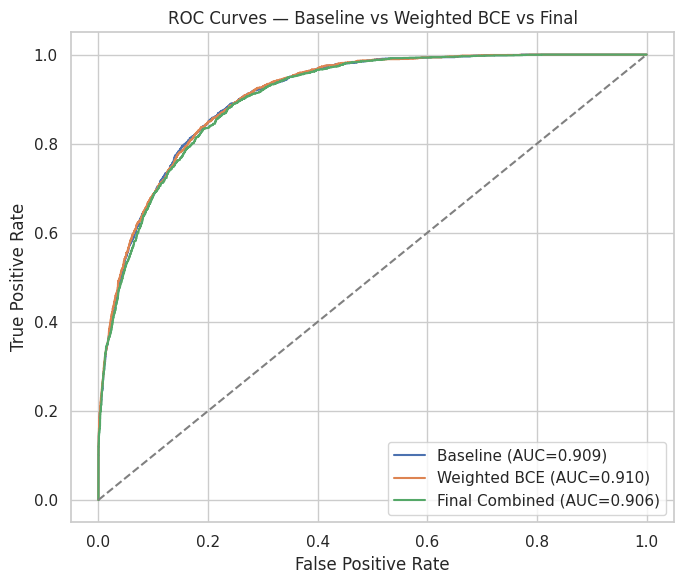

Saved results_table.csv


In [ ]:
# Final comparison table (results come from the current run).
results_df = pd.DataFrame(results)
results_df = results_df.drop_duplicates(subset=["Model"], keep="last")
display(results_df.style.highlight_max(subset=["F1(1)", "ROC-AUC"], color="#ffcccc")
        .format({c:"{:.3f}" for c in ["Test Acc","Prec(1)","Recall(1)","F1(1)","ROC-AUC"]}))

# ROC curve: baseline, weighted BCE, final combined.
plt.figure(figsize=(7,6))
for label, probs in [
    ("Baseline", base_prob),
    ("Weighted BCE", prob_wbce),
    ("Final Combined", final_prob)
]:
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    plt.plot(fpr, tpr, label=f"{label} (AUC={auc:.3f})")
plt.plot([0,1], [0,1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Baseline vs Weighted BCE vs Final")
plt.legend(); plt.tight_layout(); plt.show()

# Export the results table for the project repository.
results_df.to_csv("results_table.csv", index=False)
print("Saved results_table.csv")